### Reconnaissance des émotions faciales avec CNN, par Modi et al.

In [3]:
# ---IMPORTATIONS ET CONFIGURATION CPU ---
import os # Permet de gérer les chemins de fichiers et dossiers sur le système
import time # Permet de mesurer précisément le temps d'entraînement de chaque époque
import numpy as np # Bibliothèque de calcul matriciel 
import matplotlib.pyplot as plt # affichage les courbes et la matrice de confusion
import torch # Cœur du framework PyTorch pour le calcul tensoriel et le Deep Learning
import torch.nn as nn # Contient les briques de réseaux de neurones (Conv2d, Linear, CrossEntropyLoss...)
import torch.optim as optim # Contient les algorithmes d'optimisation (AdamW)
from torch.utils.data import DataLoader # Gère le découpage des données en mini-lots (batches)
from torchvision import datasets, transforms # Outils dédiés à la vision par ordinateur
import timm # Bibliothèque de référence contenant les architectures Vision Transformers (MobileViT, ViT)
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay # Métriques scientifiques
import cv2 # OpenCV : utilisé pour la détection de visage en temps réel via webcam
from PIL import Image # Python Imaging Library : permet de manipuler les images au format PIL
from sklearn.metrics import accuracy_score, f1_score
# Sélectionne automatiquement le processeur (CPU)
device = torch.device("cpu")

# Optimise l'utilisation de cpu
torch.set_num_threads(os.cpu_count())
print(f"Matériel utilisé : {device} | Cœurs CPU activés : {torch.get_num_threads()}")

Matériel utilisé : cpu | Cœurs CPU activés : 4


In [4]:
# ---PRÉTRAITEMENT DU DATASET ---
DATA_DIR = "./dataset" 
BATCH_SIZE = 64 # Lots de 64 images

# on Choisis d'abord "cnn" (Modi et al., très rapide ~15 min) et "vit" après (MobileViT inspiré de Xue et al., ~35 min)
MODEL_CHOICE = "cnn" 

# Résolution adaptée au modèle : 48x48 (natif FER-2013) pour le CNN, 128x128 pour le Transformer léger
IMG_SIZE = 48 if MODEL_CHOICE == "cnn" else 128

# 1. Pipeline de transformations pour l'entraînement (Data Augmentation pour éviter le surapprentissage)
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), # Redimensionne l'image à la taille optimale pour le CPU
    transforms.RandomHorizontalFlip(p=0.5), # Symétrie miroir horizontale (50% de chance) : conserve l'émotion (Li & Deng, 2020)
    transforms.RandomRotation(degrees=15), # Rotation aléatoire de -15° à +15° pour simuler l'inclinaison de la tête
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # Variation légère de luminosité/contraste (Szeliski, 2022)
    transforms.ToTensor(), # Convertit l'image (0-255) en Tenseur PyTorch normalisé entre 0.0 et 1.0
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Standardisation statistique ImageNet
])

# 2. Pipeline pour la validation (aucune modification aléatoire pour évaluer le modèle sur des images réelles)
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), # Redimensionne uniquement
    transforms.ToTensor(), # Convertit en Tenseur
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Applique la même standardisation
])

# 3. Chargement des images depuis les dossiers
train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=train_transforms)
val_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "val"), transform=val_transforms)

# 4. Création des DataLoaders (num_workers=0 évite les surcharges de mémoire sur CPU sous JupyterLab)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

class_names = train_dataset.classes # Récupère automatiquement la liste des 7 émotions (noms des dossiers)
print(f"Modèle sélectionné : {MODEL_CHOICE.upper()} | Résolution : {IMG_SIZE}x{IMG_SIZE}")
print(f"Classes détectées ({len(class_names)}) : {class_names}")
print(f"Images d'entraînement : {len(train_dataset)} | Images de validation : {len(val_dataset)}")

Modèle sélectionné : CNN | Résolution : 48x48
Classes détectées (7) : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Images d'entraînement : 28709 | Images de validation : 7178


In [5]:
# --- DÉFINITION DES 2 ARCHITECTURES  ---

# ARCHITECTURE 1 : Réseau de Neurones Convolutif (Inspiré de Modi & Bohara, 2021 et Goodfellow et al., 2016)
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(EmotionCNN, self).__init__() # Initialise la classe parente nn.Module de PyTorch
        
        # Extracteur de caractéristiques locales (contours des yeux, courbure de la bouche, sourcils)
        self.features = nn.Sequential(
            # Bloc 1 : 3 canaux RGB -> 32 cartes de caractéristiques
            nn.Conv2d(3, 32, kernel_size=3, padding=1), # Convolution 3x3 conservant la taille spatiale (padding=1)
            nn.BatchNorm2d(32), # Normalisation par lot : stabilise et accélère l'apprentissage 
            nn.ReLU(inplace=True), # Fonction d'activation Rectified Linear Unit : introduit la non-linéarité
            nn.MaxPool2d(kernel_size=2, stride=2), # Sous-échantillonnage : divise largeur et hauteur par 2 (48 -> 24)

            # Bloc 2 : 32 -> 64 filtres
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), # Résolution passe de 24x24 à 12x12

            # Bloc 3 : 64 -> 128 filtres
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), # Résolution passe de 12x12 à 6x6

            # Bloc 4 : 128 -> 256 filtres
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)) # Global Average Pooling : compresse chaque carte 6x6 en une moyenne 1x1
        )
        
        # Classifieur final
        self.classifier = nn.Sequential(
            nn.Flatten(), # Transforme le tenseur (Batch, 256, 1, 1) en vecteur plat (Batch, 256)
            nn.Dropout(p=0.5), # Régularisation : éteint aléatoirement 50% des neurones
            nn.Linear(256, 128), # Couche entièrement connectée de 256 vers 128 neurones
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes) # Couche de sortie produisant les 7 scores bruts (logits)
        )

    def forward(self, x):
        x = self.features(x) # Passe l'image dans les couches convolutives
        x = self.classifier(x) # Passe les caractéristiques extraites dans le classifieur
        return x

# ARCHITECTURE 2 : Vision Transformer Hybride Léger (Inspiré de Xue et al., 2021 et Mehta & Rastegari, 2022)
def build_vit_cpu_model(num_classes=7, pretrained=True):
    # 'mobilevit_xxs' combine des convolutions locales et des blocs Transformers d'attention globale
    # Il est ~65 fois plus léger qu'un ViT classique
    model = timm.create_model('mobilevit_xxs', pretrained=pretrained, num_classes=num_classes)
    return model

### d'abord,j'ai pris epochs 4 pour tester car 12 prenait beaucoup de temps et après avoir vu que ça marche j'ai augmenté:j'ai gardé le meilleur score pour les 4 premiers eepoches et changer epochs=8=12-4

In [6]:
# --- CELLULE 4 : BOUCLE D'ENTRAÎNEMENT ET D'ÉVALUATION SUR CPU ---

#j'ai fait EPOCHS = 4 au debut(4 passages complets sur tout le jeu d'entraînement)
#et apres j'ai gardé le best_core=48.19% tout en augmentant epochs=8(8+4=12)
EPOCHS = 8

if MODEL_CHOICE == "cnn":
    model = EmotionCNN(num_classes=len(class_names)).to(device) # Initialise le CNN
    learning_rate = 1e-3 # Taux d'apprentissage standard (0.001) pour un réseau entraîné depuis zéro
else:
    model = build_vit_cpu_model(num_classes=len(class_names), pretrained=True).to(device) # Initialise MobileViT
    learning_rate = 3e-4 # Taux adapté pour affiner (Fine-Tuning) les poids pré-entraînés

criterion = nn.CrossEntropyLoss() # Fonction de perte (combine LogSoftmax et entropie croisée - Bishop, 2006)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4) # Optimiseur avec régularisation L2

# Listes pour stocker l'historique afin de tracer les courbes après
history = {'train_loss': [], 'val_acc': []}


print("Début de l'entraînement...")
# 1. Recharge les poids du meilleur modèle sauvegardé lors des 4 premières époques
model.load_state_dict(torch.load(f"modelsest_{MODEL_CHOICE}_emotion.pth", map_location=device))
#best_acc = 0.0 pour epochs= 4 et là je commence avec  la meilleure score obtenue avec EPOCHS=4

best_acc = 0.4819
for epoch in range(EPOCHS):
    start_time = time.time() # Démarre le chronomètre de l'époque
    
    # --- PHASE D'ENTRAÎNEMENT ---
    model.train() # Active le mode entraînement (active Dropout et BatchNorm)
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device) # Prépare le lot d'images et d'étiquettes
        
        optimizer.zero_grad() # Réinitialise les gradients à zéro avant chaque nouveau lot
        outputs = model(images) # Propagation avant (Forward pass) : calcule les prédictions
        loss = criterion(outputs, labels) # Calcule l'erreur entre prédictions et vraies émotions
        loss.backward() # Rétropropagation  : calcule les gradients
        optimizer.step() # Met à jour les poids du réseau dans la direction qui réduit l'erreur
        
        running_loss += loss.item() # Cumule la perte du lot
        
    epoch_loss = running_loss / len(train_loader) # Calcule la perte moyenne sur l'époque
    
    # --- PHASE DE VALIDATION ---
    model.eval() # Passe en mode évaluation (désactive le Dropout)
    all_preds, all_labels = [], []
    
    with torch.no_grad(): # Désactive le calcul de gradients
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images) # Prédiction sur les données de validation
            _, preds = torch.max(outputs, 1) # Sélectionne l'indice de la classe ayant le score le plus élevé
            
            all_preds.extend(preds.numpy()) # Stocke les prédictions
            all_labels.extend(labels.numpy()) # Stocke les vraies étiquettes
            
    val_acc = np.mean(np.array(all_preds) == np.array(all_labels)) # Calcule le pourcentage de bonnes prédictions
    elapsed = time.time() - start_time # Calcule la durée de l'époque en secondes
    
    history['train_loss'].append(epoch_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Époque [{epoch+1}/{EPOCHS}] ({elapsed:.0f}s) | Perte Train: {epoch_loss:.4f} | Précision Val: {val_acc*100:.2f}%")
    
    # Sauvegarde automatique des poids si le modèle bat son record de précision
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), f"modelsest_{MODEL_CHOICE}_emotion.pth")

print(f"\nEntraînement terminé ! Meilleure précision sauvegardée : {best_acc*100:.2f}%")

Début de l'entraînement sur CPU...
Époque [1/8] (217s) | Perte Train: 1.0692 | Précision Val: 59.85%
Époque [2/8] (219s) | Perte Train: 1.0501 | Précision Val: 59.47%
Époque [3/8] (224s) | Perte Train: 1.0409 | Précision Val: 59.38%
Époque [4/8] (228s) | Perte Train: 1.0345 | Précision Val: 61.23%
Époque [5/8] (302s) | Perte Train: 1.0223 | Précision Val: 59.42%
Époque [6/8] (195s) | Perte Train: 1.0119 | Précision Val: 60.96%
Époque [7/8] (196s) | Perte Train: 1.0096 | Précision Val: 61.28%
Époque [8/8] (205s) | Perte Train: 0.9981 | Précision Val: 62.13%

Entraînement terminé ! Meilleure précision sauvegardée : 62.13%


Rapport de classification détaillé :

              precision    recall  f1-score   support

       angry       0.54      0.56      0.55       958
     disgust       0.70      0.19      0.30       111
        fear       0.53      0.26      0.35      1024
       happy       0.80      0.87      0.83      1774
     neutral       0.53      0.65      0.58      1233
         sad       0.50      0.50      0.50      1247
    surprise       0.70      0.81      0.75       831

    accuracy                           0.62      7178
   macro avg       0.61      0.55      0.55      7178
weighted avg       0.61      0.62      0.61      7178

Graphiques sauvegardés avec succès sous : resultats_cnn_emotion.png


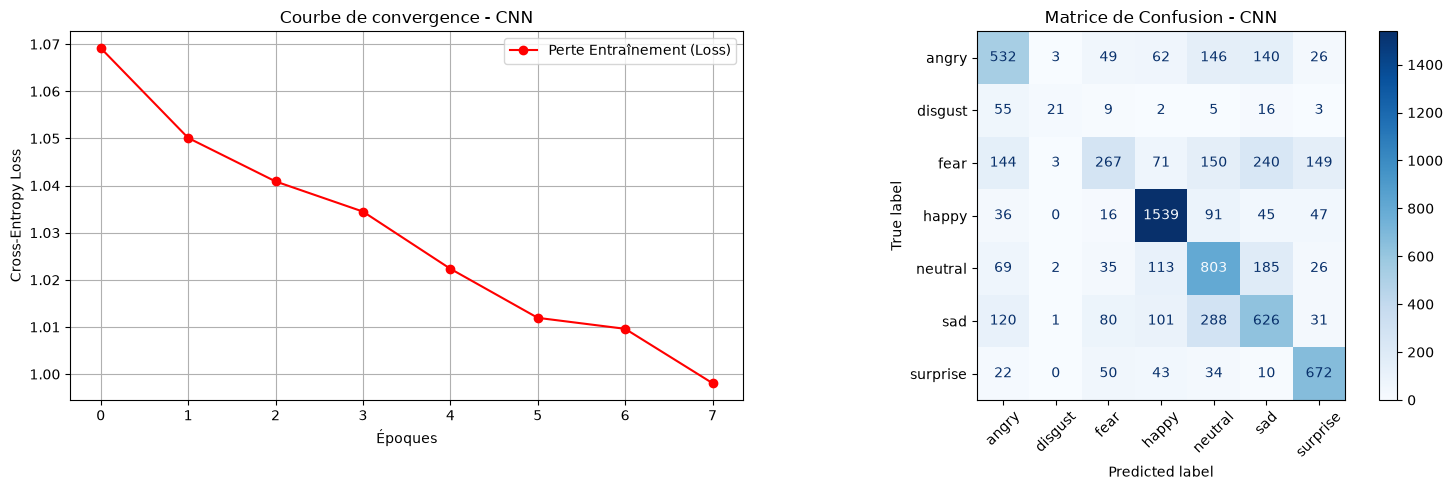

In [7]:
# ---ANALYSE DES RÉSULTATS ---

# 1. Affichage du rapport complet (Précision, Rappel, F1-Score par émotion)
print("Rapport de classification détaillé :\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 2. Traçage des graphiques
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique de gauche : Évolution de la perte d'entraînement
axes[0].plot(history['train_loss'], label='Perte Entraînement (Loss)', color='red', marker='o')
axes[0].set_title(f'Courbe de convergence - {MODEL_CHOICE.upper()}')
axes[0].set_xlabel('Époques')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True)

# Graphique de droite : Matrice de confusion (montre quelles émotions sont confondues entre elles)
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=axes[1], cmap='Blues', xticks_rotation=45)
axes[1].set_title(f'Matrice de Confusion - {MODEL_CHOICE.upper()}')

plt.tight_layout()
#SAUVEGARDE EN image
nom_fichier = f"resultsesultats_{MODEL_CHOICE}_emotion.png"
plt.savefig(nom_fichier, dpi=300, bbox_inches='tight')
print(f"Graphiques sauvegardés avec succès sous : {nom_fichier}")
plt.show()

In [6]:
# ---  DÉTECTION EN DIRECT VIA WEBCAM ---

# 1. Création de la structure vide du modèle en mémoire
if MODEL_CHOICE == "cnn":
    model = EmotionCNN(num_classes=len(class_names)).to(device)
else:
    model = build_vit_cpu_model(num_classes=len(class_names), pretrained=False).to(device)

# 2. Chargement des poids entraînés depuis votre fichier sauvegardé
model.load_state_dict(torch.load(f"best_{MODEL_CHOICE}_emotion.pth", map_location=device))
model.eval()


# 2. Chargement du détecteur de visages Haar Cascade (Viola & Jones, 2001) inclus dans OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# 3. Démarrage de la caméra (0 = webcam intégrée par défaut)
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read() # Capture une image (frame) du flux vidéo
    if not ret:
        print("Erreur d'accès à la webcam.")
        break
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) # Convertit en niveaux de gris pour accélérer la détection de visage
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5) # Détecte les visages (x, y, largeur, hauteur)
    
    for (x, y, w, h) in faces:
        face_roi = frame[y:y+h, x:x+w] # Découpe uniquement la zone du visage (Region of Interest)
        face_rgb = cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB) # Convertit l'ordre des couleurs BGR (OpenCV) vers RGB (PyTorch)
        pil_img = Image.fromarray(face_rgb) # Transforme le tableau NumPy en image PIL
        
        # Applique les transformations de validation et ajoute la dimension de lot (1, 3, IMG_SIZE, IMG_SIZE)
        input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            outputs = model(input_tensor) # Prédiction instantanée sur CPU
            probabilities = torch.nn.functional.softmax(outputs, dim=1) # Convertit les logits en probabilités (0 à 1)
            confidence, predicted_idx = torch.max(probabilities, 1) # Récupère l'émotion la plus probable et son score
            
        label = f"{class_names[predicted_idx.item()]} ({confidence.item()*100:.1f}%)"
        
        # Dessine un cadre vert autour du visage et affiche l'émotion détectée
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)
        cv2.putText(frame, label, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        
    cv2.imshow('Reconnaissance des Emotions - CPU (Appuyez sur Q pour quitter)', frame)
    
    # Attend 1 ms et vérifie si la touche 'q' est pressée
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release() # Libère la webcam
cv2.destroyAllWindows() # Ferme la fenêtre OpenCV

# Note : Une fenêtre externe OpenCV va s'ouvrir. Appuyez sur la touche 'q' de votre clavier pour la fermer.